# 2. Exploratory Data Analysis: which columns do we really need?

**The question this notebook answers:** the data has 11 input columns. Which of them actually help us predict sales, and which can we throw away?

We do not decide this by guessing. We *discover* it step by step, and every claim is backed by a chart or a number:

1. Look at the target (sales).
2. Look at the columns one by one (the usual first look).
3. Notice that **sales = price x units sold**, so the real thing to explain is *units sold*.
4. Test every column against *units sold*.
5. Take the **store** out (it turns out to dominate everything) and test every column again.
6. Zoom in on the one column that survives: the **item number**.
7. Check that nothing useful is left over.
8. Final proof: add each dropped column back into a model. Does the score improve?
9. The decision: which columns we keep and why.

The input is `train_cl.csv`, the cleaned file produced by `1. Colab_Data_Cleaning.ipynb`.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("train_cl.csv")
target = "Item_Outlet_Sales"
print(train.shape)
train.head()

(8523, 12)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.022911,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.016164,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## Step 1: The target (sales)

Before looking at any column, look at what we are trying to predict. *Skewness* measures how lopsided a distribution is: 0 means symmetric, a large positive number means a long tail of very big values.

=== Target Skewness ===
Original: 1.1775
Log1p:    -0.8823


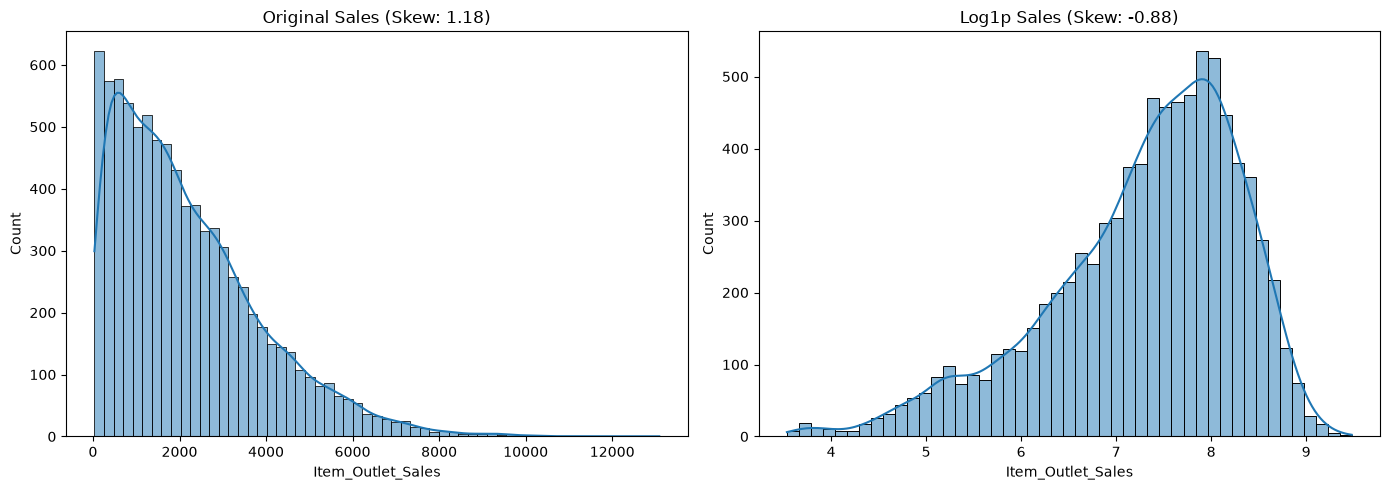

In [2]:
skew_orig = train[target].skew()
skew_log = np.log1p(train[target]).skew()

print("=== Target Skewness ===")
print(f"Original: {skew_orig:.4f}")
print(f"Log1p:    {skew_log:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train[target], kde=True, ax=axes[0])
axes[0].set_title(f"Original Sales (Skew: {skew_orig:.2f})")

sns.histplot(np.log1p(train[target]), kde=True, ax=axes[1])
axes[1].set_title(f"Log1p Sales (Skew: {skew_log:.2f})")

plt.tight_layout()
plt.show()

**What we learn:** most rows sell a small amount, a few sell more than 10,000 (skew 1.18). Because the score (RMSE) squares every error, those few big rows matter most. Taking the log over-corrects (skew -0.88), so it is not a clean fix, and we keep sales on its own scale.

## Step 2: A first look at the columns

The usual first questions: do the store columns and the price column relate to sales?

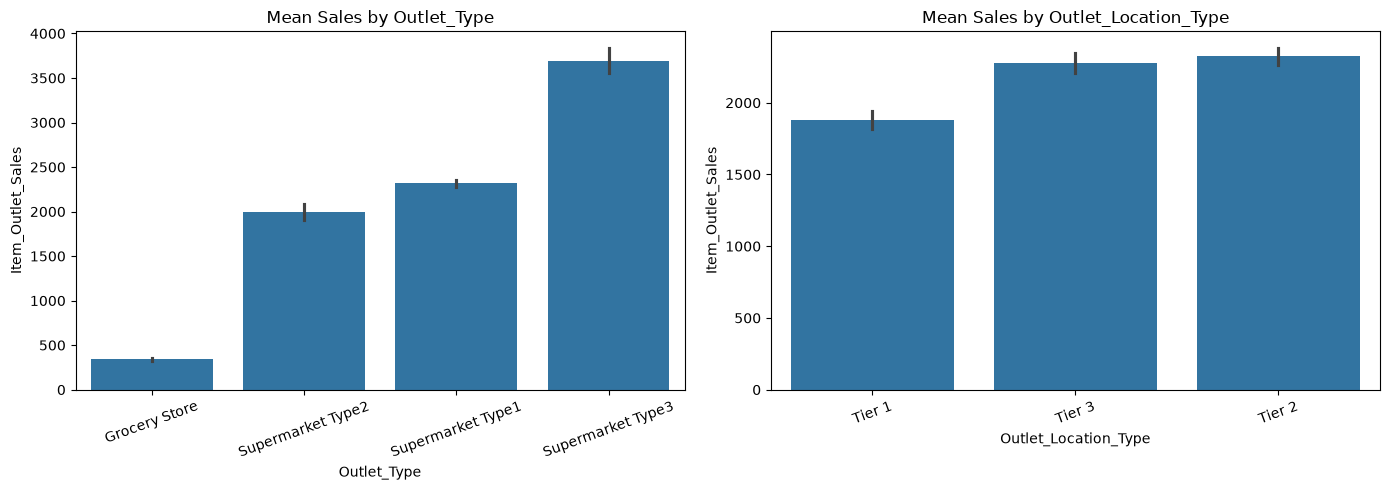

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ["Outlet_Type", "Outlet_Location_Type"]):
    order = train.groupby(col)[target].mean().sort_values().index
    sns.barplot(data=train, x=col, y=target, order=order, ax=ax)
    ax.set_title(f"Mean Sales by {col}")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

**What we learn:** the type of store matters a lot (grocery stores sell about 340 per row, Supermarket Type 3 about 3,700). The location tier matters much less. So *which store* a row belongs to is clearly important. Keep this in mind for Step 4.

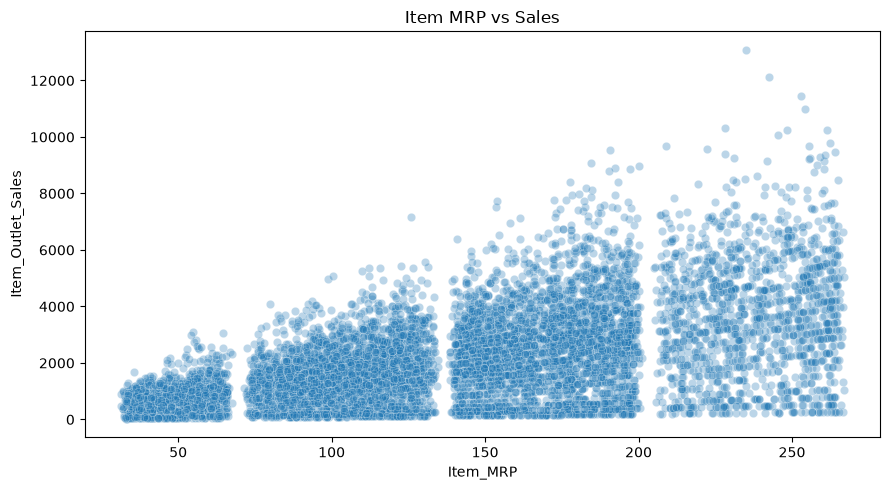

In [4]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=train, x="Item_MRP", y=target, alpha=0.3)
plt.title("Item MRP vs Sales")
plt.tight_layout()
plt.show()

**What we learn:** more expensive items sell for more, and the cloud fans out as the price rises. That fan shape is a hint: sales look like *price times something random*. We follow this up in Step 3.

Now the printed statistics: how are the item codes split, and does the fat-content label make sense for every item?

In [5]:
train["Item_Cat"] = train["Item_Identifier"].str[:2]

print("=== Item Category Counts ===")
print(train["Item_Cat"].value_counts())

print("\n=== Fat Content in NC Items ===")
print(train.loc[train["Item_Cat"] == "NC", "Item_Fat_Content"].value_counts())

=== Item Category Counts ===
Item_Cat
FD    6125
NC    1599
DR     799
Name: count, dtype: int64

=== Fat Content in NC Items ===
Item_Fat_Content
Low Fat    1599
Name: count, dtype: int64


**What we learn:** the first two letters of the code split items into food (FD), non-consumable (NC) and drinks (DR). All 1,599 non-consumable rows are labelled 'Low Fat', which makes no sense for something you cannot eat, so the fat label carries no real information for them. A first warning that `Item_Fat_Content` may not be useful.

In [6]:
numeric_cols = [
    "Item_Weight",
    "Item_Visibility",
    "Item_MRP",
    "Outlet_Establishment_Year"
]

corrs = train[numeric_cols].corrwith(train[target])

print("=== Correlations with Sales ===")
print(corrs.sort_values(ascending=False))

=== Correlations with Sales ===
Item_MRP                     0.567574
Item_Weight                  0.013162
Outlet_Establishment_Year   -0.049135
Item_Visibility             -0.126026
dtype: float64


**What we learn:** a *correlation* of 0 means no straight-line link, +1 or -1 a perfect one. Only the price (0.57) has a real link with sales. Weight (0.01), store opening year (-0.05) and visibility (-0.13) are weak. But a correlation only sees straight lines and ignores everything else, so this is a hint, not a proof. We test properly in Steps 4 to 8.

In [7]:
outlet_sales = train.groupby(
    ["Outlet_Identifier", "Outlet_Type",
     "Outlet_Establishment_Year", "Outlet_Size"]
)[target].agg(["count", "mean", "std"]).reset_index()

print("=== Sales Statistics by Outlet ===")
print(outlet_sales.to_string(index=False))

=== Sales Statistics by Outlet ===
Outlet_Identifier       Outlet_Type  Outlet_Establishment_Year Outlet_Size  count        mean         std
           OUT010     Grocery Store                       1998       Small    555  339.351662  271.014855
           OUT013 Supermarket Type1                       1987        High    932 2298.995256 1533.531664
           OUT017 Supermarket Type1                       2007       Small    926 2340.675263 1550.778025
           OUT018 Supermarket Type2                       2009      Medium    928 1995.498739 1375.932889
           OUT019     Grocery Store                       1985       Small    528  340.329723  249.979449
           OUT027 Supermarket Type3                       1985      Medium    935 3694.038558 2127.760054
           OUT035 Supermarket Type1                       2004       Small    930 2438.841866 1538.512533
           OUT045 Supermarket Type1                       2002       Small    929 2192.384798 1462.399658
           

**What we learn:** each store has 900+ rows (the two grocery stores about 540). Average sales fall into three levels: grocery stores about 340, ordinary supermarkets about 2,000 to 2,450, and OUT027 about 3,700. The *store* sets the level of sales. Notice also that type, size and opening year are the same for every row of a store: they are just labels *of the store*.

## Step 3: Sales = price x units sold

Sales are what a store takes in. That is the price of the item times the number of units sold. So we can compute the **units sold** for every row: `units = sales / price`. If this is right, price should explain *sales* (it scales them) but not *units*.

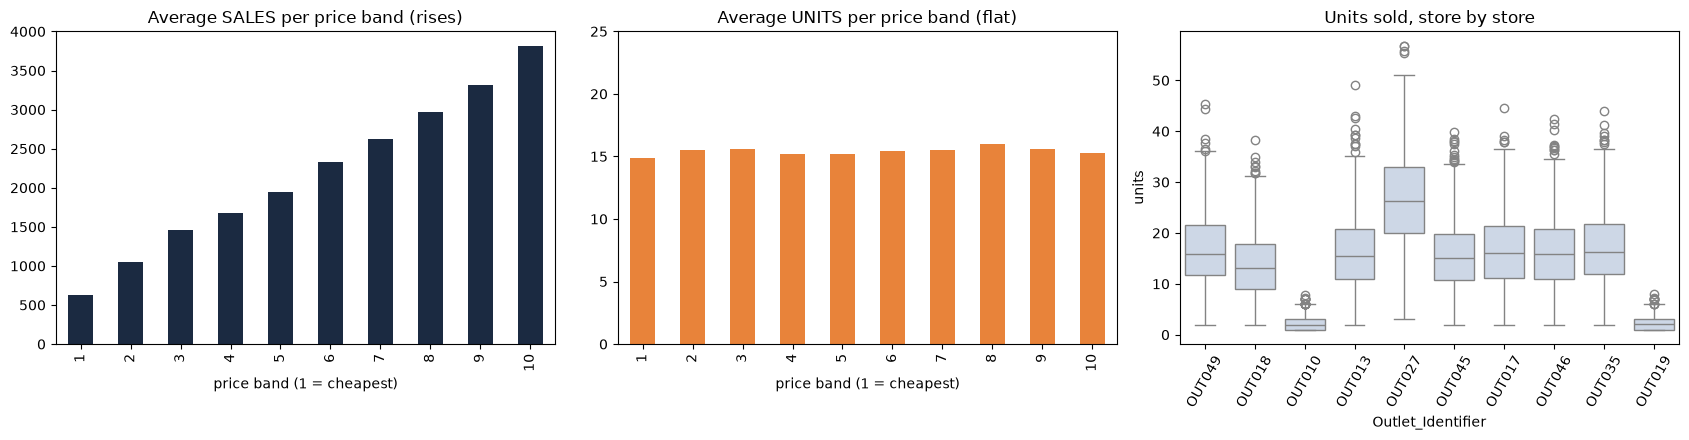

In [8]:
train["units"] = train["Item_Outlet_Sales"] / train["Item_MRP"]
price_band = pd.qcut(train["Item_MRP"], 10, labels=range(1, 11))   # 10 equal-sized price bands, 1 = cheapest

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

train.groupby(price_band, observed=True)[target].mean().plot(kind="bar", ax=axes[0], color="#1B2A41")
axes[0].set_title("Average SALES per price band (rises)")
axes[0].set_xlabel("price band (1 = cheapest)")

train.groupby(price_band, observed=True)["units"].mean().plot(kind="bar", ax=axes[1], color="#E8833A")
axes[1].set_title("Average UNITS per price band (flat)")
axes[1].set_xlabel("price band (1 = cheapest)")
axes[1].set_ylim(0, 25)

sns.boxplot(data=train, x="Outlet_Identifier", y="units", ax=axes[2], color="#C9D6EA")
axes[2].set_title("Units sold, store by store")
axes[2].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

**What we learn:**
- Left: average sales climb steadily with price. Middle: average **units do not move at all** (about 15 in every band). So price does not make people buy more, it only multiplies the units into sales.
- Right: units depend strongly on the **store** (about 2.4 for the two grocery stores, about 16 for most supermarkets, 26.6 for OUT027).

One more check that `units` is something real. If units are counts of items sold, they should sit close to whole numbers more often than chance.

Rows whose units are within 0.02 of a whole number: 17.6%   (pure chance would give about 4%)


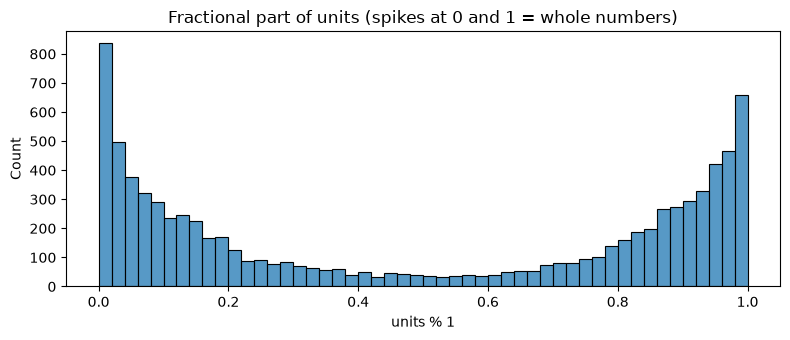

In [9]:
fraction = train["units"] % 1
close_to_whole = (np.minimum(fraction, 1 - fraction) < 0.02).mean()
print(f"Rows whose units are within 0.02 of a whole number: {close_to_whole:.1%}   (pure chance would give about 4%)")

plt.figure(figsize=(8, 3.5))
sns.histplot(fraction, bins=50)
plt.title("Fractional part of units (spikes at 0 and 1 = whole numbers)")
plt.xlabel("units % 1")
plt.tight_layout()
plt.show()

**What we learn:** units pile up at whole numbers (17.6% of rows against about 4% by chance), so they really are item counts. Sales = price x a whole number of items. **We will predict units and multiply by price at the end.** Price therefore has one job: it is the multiplier that turns units back into sales.

## Step 4: Which columns explain units sold?

Now test *every* candidate column against `units`. We need one fair yardstick that works for numbers and for categories alike:

- Group the rows by the column (numbers are cut into 10 equal-sized bands first).
- Measure how much of the variation in units the groups explain: 0 = nothing, 1 = everything.
- Compare with **chance**: shuffle the units randomly 200 times and see how much a column "explains" by luck alone. Columns with many groups (like the full item code, 1,559 groups of about 5 rows) explain a lot by luck, so this comparison is essential.

The result is shown as *how many times stronger than chance* a column is. 1x = no better than luck.

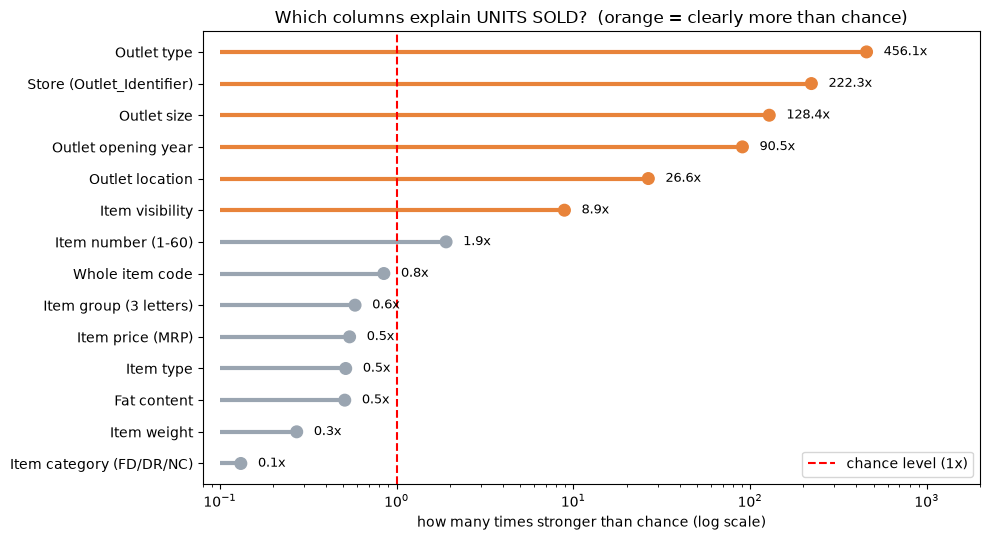

,column,share_explained,chance_level,times_stronger_than_chance
0,Outlet type,0.4267,0.0009,456.1195
1,Store (Outlet_Identifier),0.4284,0.0019,222.2788
2,Outlet size,0.0841,0.0007,128.4038
3,Outlet opening year,0.1548,0.0017,90.5068
4,Outlet location,0.0206,0.0008,26.5686
5,Item visibility,0.0193,0.0022,8.9050
6,Item number (1-60),0.0170,0.0089,1.9057
7,Whole item code,0.1626,0.1919,0.8470
8,Item group (3 letters),0.0062,0.0107,0.5821
9,Item price (MRP),0.0010,0.0019,0.5421


In [10]:
train["item_number"] = train["Item_Identifier"].str[3:].astype(int)   # the 15 in FDA15
train["item_category"] = train["Item_Identifier"].str[:2]               # FD / DR / NC
train["item_group"] = train["Item_Identifier"].str[:3]                  # FDA, DRC, NCL ...

candidates = {
    "Store (Outlet_Identifier)": "Outlet_Identifier",
    "Outlet type": "Outlet_Type",
    "Outlet size": "Outlet_Size",
    "Outlet location": "Outlet_Location_Type",
    "Outlet opening year": "Outlet_Establishment_Year",
    "Item price (MRP)": "Item_MRP",
    "Item weight": "Item_Weight",
    "Item visibility": "Item_Visibility",
    "Fat content": "Item_Fat_Content",
    "Item type": "Item_Type",
    "Item category (FD/DR/NC)": "item_category",
    "Item group (3 letters)": "item_group",
    "Item number (1-60)": "item_number",
    "Whole item code": "Item_Identifier",
}


def share_explained(groups, values):
    """Share of the variation in `values` explained by which group a row is in (0 = nothing, 1 = everything)."""
    codes = pd.factorize(groups)[0]
    count = np.bincount(codes)
    total = np.bincount(codes, weights=values)
    return np.sum(count * (total / count - values.mean()) ** 2) / np.sum((values - values.mean()) ** 2)


def relevance(target_column, n_shuffles=200):
    rng = np.random.default_rng(0)
    values = train[target_column].values
    rows = []
    for label, column in candidates.items():
        groups = train[column]
        if groups.dtype.kind == "f":                      # decimal columns: cut into 10 equal-sized bands
            groups = pd.qcut(groups, 10, duplicates="drop")
        observed = share_explained(groups, values)
        by_chance = [share_explained(groups, rng.permutation(values)) for _ in range(n_shuffles)]
        rows.append([label, observed, np.percentile(by_chance, 95)])
    result = pd.DataFrame(rows, columns=["column", "share_explained", "chance_level"])
    result["times_stronger_than_chance"] = result["share_explained"] / result["chance_level"]
    return result.sort_values("times_stronger_than_chance", ascending=False).reset_index(drop=True)


def plot_relevance(result, title):
    result = result.iloc[::-1].reset_index(drop=True)
    shown = result["times_stronger_than_chance"].clip(lower=0.1)          # keep zeros visible on the log axis
    colors = ["#E8833A" if t > 2 else "#9AA5B1" for t in result["times_stronger_than_chance"]]
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.hlines(range(len(result)), 0.1, shown, colors=colors, linewidth=3)
    ax.scatter(shown, range(len(result)), c=colors, s=70, zorder=3)
    for i, t in enumerate(result["times_stronger_than_chance"]):
        ax.text(max(t, 0.1) * 1.25, i, f"{t:.1f}x", va="center", fontsize=9)
    ax.axvline(1, color="red", linestyle="--", label="chance level (1x)")
    ax.set_yticks(range(len(result)))
    ax.set_yticklabels(result["column"])
    ax.set_xscale("log")
    ax.set_xlim(0.08, 2000)
    ax.set_xlabel("how many times stronger than chance (log scale)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


units_result = relevance("units")
plot_relevance(units_result, "Which columns explain UNITS SOLD?  (orange = clearly more than chance)")
units_result.round(4)

**What we learn:**
- The **store** is by far the strongest column: it explains 43% of all the variation in units (over 200 times what luck gives).
- Outlet type explains almost exactly as much (it is the store with the five similar Type 1 supermarkets lumped together). Opening year, size and location explain less. All four are just coarser versions of the store (one store = one type, one size, one year). Once we know the store, they add nothing new. This is why we keep the store and drop them.
- **Item visibility looks relevant** (about 9 times chance). Hold that thought: it is suspicious, and Step 5 explains it.
- The item number is only 1.9 times chance here, because the large store differences swamp everything. Step 5 shows it properly.
- The whole item code looks like 1x: 1,559 groups of about 5 rows can explain 19% by luck alone, and the real value is no higher.

## Step 5: Take the store out, then test again

The store dominates, so it can hide or fake the effect of every other column. Fix: express each row's units *relative to its own store*: `relative_units = units / (average units of that store)`. A value of 1.0 means "a normal row for that store". Now the store differences are gone and any remaining pattern has to come from something else.

First, the suspicious visibility result. Is visibility just a store effect in disguise?

In [11]:
train["relative_units"] = train["units"] / train.groupby("Outlet_Identifier")["units"].transform("mean")

print("Average relative units per store (should all be 1.0):")
print(train.groupby("Outlet_Identifier")["relative_units"].mean().round(3).to_dict())

print("\nAverage item visibility by store type:")
print(train.groupby("Outlet_Type")["Item_Visibility"].mean().round(4))

Average relative units per store (should all be 1.0):
{'OUT010': 1.0, 'OUT013': 1.0, 'OUT017': 1.0, 'OUT018': 1.0, 'OUT019': 1.0, 'OUT027': 1.0, 'OUT035': 1.0, 'OUT045': 1.0, 'OUT046': 1.0, 'OUT049': 1.0}

Average item visibility by store type:
Outlet_Type
Grocery Store        0.1081
Supermarket Type1    0.0655
Supermarket Type2    0.0663
Supermarket Type3    0.0634
Name: Item_Visibility, dtype: float64


**What we learn:** visibility is much higher in grocery stores (about 0.108) than in supermarkets (about 0.065), and grocery stores also sell far fewer units. So visibility only *looked* relevant because it tracks the store. This is a classic trap: a column can look important simply because it is tangled up with something else. The next chart shows what is left once the store is removed.

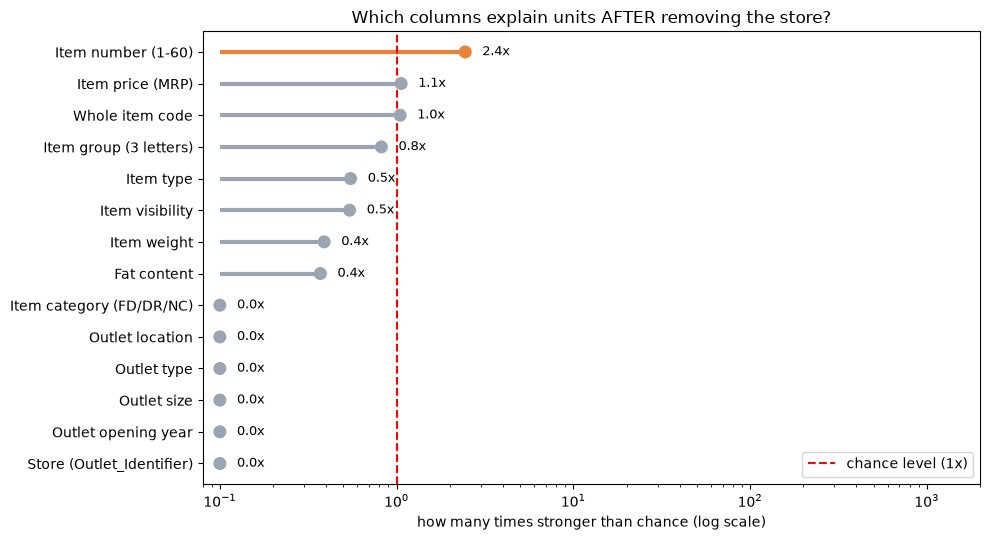

,column,share_explained,chance_level,times_stronger_than_chance
0,Item number (1-60),0.0225,0.0092,2.4431
1,Item price (MRP),0.0020,0.0019,1.0608
2,Whole item code,0.2023,0.1931,1.0473
3,Item group (3 letters),0.0084,0.0103,0.8204
4,Item type,0.0015,0.0027,0.5493
5,Item visibility,0.0010,0.0019,0.5424
6,Item weight,0.0008,0.0020,0.3892
7,Fat content,0.0002,0.0004,0.3704
8,Item category (FD/DR/NC),0.0000,0.0008,0.0125
9,Outlet location,0.0000,0.0007,0.0000


In [12]:
relative_result = relevance("relative_units")
plot_relevance(relative_result, "Which columns explain units AFTER removing the store?")
relative_result.round(4)

**What we learn:**
- Every store column (store, type, size, location, year) drops to 0. That is expected: after dividing by the store average, nothing about the store can be left.
- **Visibility falls to chance level**: it was only a store effect.
- Weight, fat content, item type, the item category and the 3-letter item group are all at chance level. They carry no information about demand.
- The price is at about 1x: it does not predict units (as Step 3 showed).
- The whole item code is at 1x: knowing *which exact item* it is tells us nothing beyond luck.
- **Only one column stands out: the item number** (the 15 in `FDA15`), about 2.4 times what chance gives, while everything else is at or below about 1.1 times. The 3-letter group in front of the number is at chance, so it is the *number* that matters, not the product family. This is the real discovery. (Step 8 confirms it with a separate test.)

## Step 6: The item number

The item number runs from 1 to 60 and the same number appears in food, drink and non-consumable codes (FDA15, DRC15, NCB15 all share 15), so each number has about 140 rows behind it. For each number, take the average relative units. If numbers did not matter, the averages would wobble around 1.0 only by chance. The grey band shows how far they should wobble by chance alone.

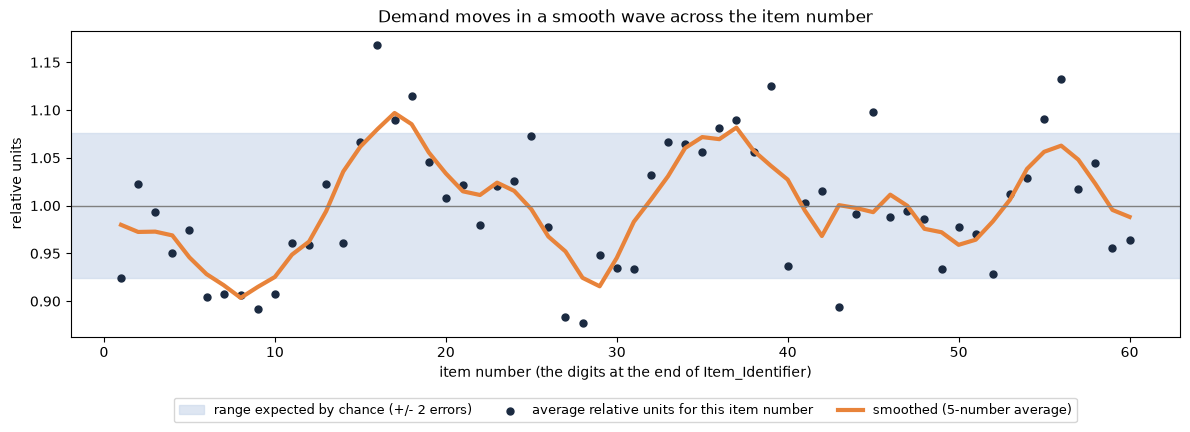

Spread of the 60 averages: 0.069
Spread when values are shuffled (pure chance): average 0.038, largest of 500 shuffles 0.049
Shuffles at least as large as the real one: 0 of 500

Correlation of the wave between food (FD) and drinks (DR): 0.53


In [13]:
by_number = train.groupby("item_number")["relative_units"].agg(["mean", "count"])
chance_error = train["relative_units"].std() / np.sqrt(by_number["count"].mean())     # normal wobble of an average
smooth_wave = by_number["mean"].rolling(5, center=True, min_periods=1).mean()          # 5-number moving average

plt.figure(figsize=(12, 4.5))
plt.axhspan(1 - 2 * chance_error, 1 + 2 * chance_error, color="#C9D6EA", alpha=0.6, label="range expected by chance (+/- 2 errors)")
plt.scatter(by_number.index, by_number["mean"], color="#1B2A41", s=25, label="average relative units for this item number")
plt.plot(smooth_wave.index, smooth_wave, color="#E8833A", linewidth=3, label="smoothed (5-number average)")
plt.axhline(1, color="grey", linewidth=1)
plt.xlabel("item number (the digits at the end of Item_Identifier)")
plt.ylabel("relative units")
plt.title("Demand moves in a smooth wave across the item number")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

# is the wiggle bigger than luck? shuffle the values and see how big the spread of the 60 averages gets
rng = np.random.default_rng(0)
observed_spread = by_number["mean"].std()
shuffled_spreads = [pd.Series(rng.permutation(train["relative_units"].values)).groupby(train["item_number"].values).mean().std()
                    for _ in range(500)]
print(f"Spread of the 60 averages: {observed_spread:.3f}")
print(f"Spread when values are shuffled (pure chance): average {np.mean(shuffled_spreads):.3f}, largest of 500 shuffles {np.max(shuffled_spreads):.3f}")
print(f"Shuffles at least as large as the real one: {(np.array(shuffled_spreads) >= observed_spread).sum()} of 500")

# is the wave a general pattern, or just one product family?
by_category = train.groupby(["item_category", "item_number"])["relative_units"].mean().unstack(0)
print("\nCorrelation of the wave between food (FD) and drinks (DR):", round(by_category["FD"].corr(by_category["DR"]), 2))

**What we learn:**
- The averages swing between about 0.90 and 1.10. 17 of the 60 dots fall outside the grey band, where pure chance would put only about 3 (1 in 20). A smooth wave is visible: numbers around 15 to 19 and 33 to 39 sell more, numbers around 5 to 10 and 27 to 31 sell less.
- Shuffling the data 500 times never produces a spread as large as the real one (real 0.069 against 0.038 on average by chance). So the wave is real.
- It shows up in both food and drinks (their waves are positively correlated), so it is a general pattern and not a quirk of one product family.
- Why did we not notice it by looking at items one by one? Each exact item has only about 5 rows, which is far too few to see a 10% effect. Pooling the 60 numbers puts about 140 rows behind each point.

This wave is smooth, so we model it with a smooth curve (a *spline*) of the item number, not with 60 separate categories. A smooth curve borrows strength from neighbouring numbers, which is exactly what makes it reliable.

## Step 7: Is anything left over after the wave?

Divide out the smoothed wave and test every column a last time.

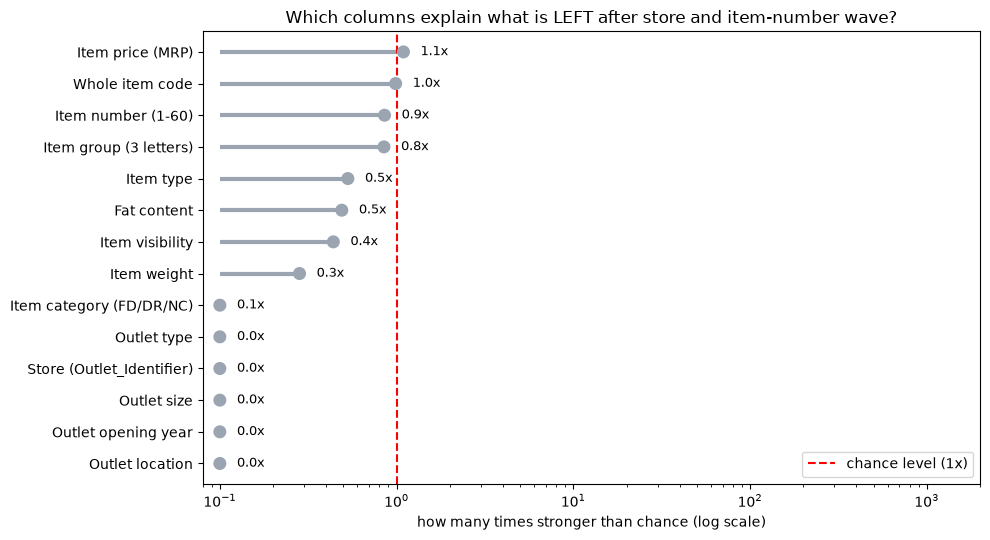

,column,share_explained,chance_level,times_stronger_than_chance
0,Item price (MRP),0.0021,0.0019,1.0935
1,Whole item code,0.1904,0.1927,0.9878
2,Item number (1-60),0.0080,0.0093,0.8546
3,Item group (3 letters),0.0086,0.0102,0.8483
4,Item type,0.0015,0.0028,0.5301
5,Fat content,0.0002,0.0004,0.4897
6,Item visibility,0.0008,0.0019,0.4386
7,Item weight,0.0005,0.0019,0.2823
8,Item category (FD/DR/NC),0.0001,0.0008,0.0864
9,Outlet type,0.0000,0.0008,0.0089


In [14]:
train["left_over"] = train["relative_units"] / train["item_number"].map(smooth_wave)

left_over_result = relevance("left_over")
plot_relevance(left_over_result, "Which columns explain what is LEFT after store and item-number wave?")
left_over_result.round(4)

**What we learn:** nothing clearly stands out any more. Everything sits close to chance level, including the item number itself (the wave has been removed) and the whole item code. The price shows only a very faint trace (about 1x) which is not convincing. What remains is random variation in how many items customers happened to buy, which no column can explain.

## Step 8: The final proof, using predictions

Statistics can mislead, so here is the test that matters. Build a small model that predicts sales as

**store average units x price x (smooth curve of the item number)**

and measure its prediction error (RMSE, 3 x 5-fold cross-validation, lower is better). Then add each dropped column to the model *one at a time*. If a column is useful, the error should fall.

Prediction error of store x price x item-number curve: 1061.9


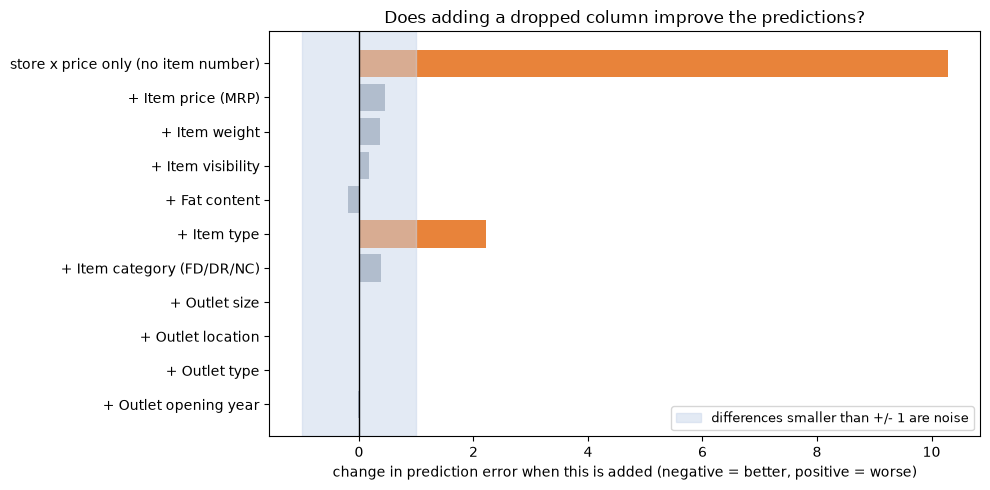

,model,change_in_error
10,+ Outlet opening year,-0.02
9,+ Outlet type,0.01
8,+ Outlet location,-0.00
7,+ Outlet size,0.01
6,+ Item category (FD/DR/NC),0.39
5,+ Item type,2.23
4,+ Fat content,-0.19
3,+ Item visibility,0.17
2,+ Item weight,0.37
1,+ Item price (MRP),0.45


In [15]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.preprocessing import SplineTransformer

curve = SplineTransformer(n_knots=16, degree=3).fit_transform(train[["item_number"]])     # smooth curve of the item number


def cv_rmse(extra_columns=None, use_curve=True, seeds=(0, 1, 2)):
    """Prediction error of: store average x price x Ridge(curve [+ extra columns]). Lower is better."""
    columns = [curve] if use_curve else []
    if extra_columns is not None:
        columns.append(extra_columns)
    X = np.hstack(columns) if columns else np.ones((len(train), 1))
    scores = []
    for seed in seeds:
        prediction = np.zeros(len(train))
        for learn, check in KFold(5, shuffle=True, random_state=seed).split(train):
            store_mean = train.iloc[learn].groupby("Outlet_Identifier")["units"].mean()
            mean_learn = train["Outlet_Identifier"].iloc[learn].map(store_mean).values
            mean_check = train["Outlet_Identifier"].iloc[check].map(store_mean).values
            model = Ridge(alpha=10).fit(X[learn], train["units"].values[learn] / mean_learn)
            prediction[check] = mean_check * model.predict(X[check]) * train["Item_MRP"].values[check]
        scores.append(np.sqrt(np.mean((train[target].values - prediction) ** 2)))
    return np.mean(scores)


def as_numbers(column):
    if not pd.api.types.is_numeric_dtype(train[column]):
        return pd.get_dummies(train[column]).astype(float).values            # text: one 0/1 column per category
    values = train[column].values.astype(float)
    return ((values - values.mean()) / values.std()).reshape(-1, 1)          # numbers: put on a common scale


base = cv_rmse()
rows = [["store x price only (no item number)", cv_rmse(use_curve=False) - base],
        ["+ Item price (MRP)", cv_rmse(as_numbers("Item_MRP")) - base]]
for label, column in [("Item weight", "Item_Weight"), ("Item visibility", "Item_Visibility"), ("Fat content", "Item_Fat_Content"),
                      ("Item type", "Item_Type"), ("Item category (FD/DR/NC)", "item_category"), ("Outlet size", "Outlet_Size"),
                      ("Outlet location", "Outlet_Location_Type"), ("Outlet type", "Outlet_Type"), ("Outlet opening year", "Outlet_Establishment_Year")]:
    rows.append(["+ " + label, cv_rmse(as_numbers(column)) - base])
change = pd.DataFrame(rows, columns=["model", "change_in_error"]).iloc[::-1]

print(f"Prediction error of store x price x item-number curve: {base:.1f}")
plt.figure(figsize=(10, 5))
plt.barh(change["model"], change["change_in_error"], color=["#E8833A" if v > 0.5 else "#9AA5B1" for v in change["change_in_error"]])
plt.axvspan(-1, 1, color="#C9D6EA", alpha=0.5, label="differences smaller than +/- 1 are noise")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("change in prediction error when this is added (negative = better, positive = worse)")
plt.title("Does adding a dropped column improve the predictions?")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()
change.round(2)

**What we learn:**
- Without the item-number curve (store x price only) the error is about 10 points *higher*. The item number is worth keeping.
- Adding any of the other columns changes the error by less than about half a point (inside the noise band), with one exception: **item type makes it about 2 points worse**. None of them improves the predictions.
- The statistics from Steps 4 to 7 and this direct test agree.

## Step 9: The decision

In [16]:
pd.set_option("display.max_colwidth", None)
decision = pd.DataFrame([
    ["Outlet_Identifier (store)", "KEEP", "Sets the level of units sold: explains 43% of the variation in units (Step 4)."],
    ["Item_MRP (price)", "KEEP, as the multiplier", "Sales = price x units. It does not predict units (Steps 3 and 5), it only turns units back into sales."],
    ["Item_Identifier, number part only", "KEEP", "The only column with a real signal once the store is removed: a smooth +/-10% wave across the numbers 1 to 60 (Steps 5 and 6)."],
    ["Outlet_Type, Outlet_Size, Outlet_Location_Type, Outlet opening year", "DROP", "Coarser labels of the store. Nothing is left after removing the store (Step 5)."],
    ["Item_Visibility", "DROP", "Looked relevant (Step 4) only because it differs between store types. At chance after removing the store (Step 5)."],
    ["Item_Weight", "DROP", "At chance level (Steps 4, 5, 7) and does not improve predictions (Step 8)."],
    ["Item_Fat_Content, Item_Type, item category and group", "DROP", "At chance level (Steps 5, 7). Item type makes predictions slightly worse (Step 8)."],
    ["Item_Identifier, letters part and whole code", "DROP", "1,559 exact items with about 5 rows each: no more than luck (Steps 4, 5, 7)."],
], columns=["column", "decision", "why (evidence)"])
decision

,column,decision,why (evidence)
0,Outlet_Identifier (store),KEEP,Sets the level of units sold: explains 43% of the variation in units (Step 4).
1,Item_MRP (price),"KEEP, as the multiplier","Sales = price x units. It does not predict units (Steps 3 and 5), it only turns units back into sales."
2,"Item_Identifier, number part only",KEEP,The only column with a real signal once the store is removed: a smooth +/-10% wave across the numbers 1 to 60 (Steps 5 and 6).
3,"Outlet_Type, Outlet_Size, Outlet_Location_Type, Outlet opening year",DROP,Coarser labels of the store. Nothing is left after removing the store (Step 5).
4,Item_Visibility,DROP,Looked relevant (Step 4) only because it differs between store types. At chance after removing the store (Step 5).
5,Item_Weight,DROP,"At chance level (Steps 4, 5, 7) and does not improve predictions (Step 8)."
6,"Item_Fat_Content, Item_Type, item category and group",DROP,"At chance level (Steps 5, 7). Item type makes predictions slightly worse (Step 8)."
7,"Item_Identifier, letters part and whole code",DROP,"1,559 exact items with about 5 rows each: no more than luck (Steps 4, 5, 7)."


## Summary

We keep **three columns**: the store, the price and the item number. Everything else is thrown away, and the evidence for each choice is above.

The model in `3. final_v2.py` therefore works like this:

1. For every store, take its typical units sold (learned from the training rows only).
2. Multiply by a smooth **item-number curve** (a Ridge model fitted on the relative units).
3. Multiply by the **price**.

That gives predicted sales. No other column is needed.